<a href="https://colab.research.google.com/github/luthfiahrahmawati982-boop/praktikum-machine-learning/blob/main/Praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PRAKTIKUM 2


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split,learning_curve
from sklearn.tree import DecisionTreeClassifier

In [10]:
from sklearn.datasets import make_classification
import numpy as np

X, y = make_classification(
    n_samples=1000,
    n_features=10,
    n_informative=6,
    weights=[0.8, 0.2],
    random_state=42
)

print("Distribusi kelas:", np.bincount(y))
print("Ukuran data:", X.shape)

Distribusi kelas: [797 203]
Ukuran data: (1000, 10)


In [11]:
X_train,X_test,y_train,y_test = train_test_split( X,y,
test_size=0.2,random_state=42,stratify=y )
print("Proporsi kelas train:",
np.bincount(y_train) / len(y_train))
print("Proporsi kelas test :",
np.bincount(y_test) / len(y_test))

Proporsi kelas train: [0.7975 0.2025]
Proporsi kelas test : [0.795 0.205]


In [15]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import learning_curve
import numpy as np

model = DecisionTreeClassifier(max_depth=4, random_state=42)

train_sizes, train_scores, val_scores = learning_curve(
    model,
    X_train,
    y_train,
    cv=5,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring="accuracy"
)

train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

print("Ukuran data training:", train_sizes)
print("Rata-rata akurasi training:", train_mean)
print("Rata-rata akurasi validasi:", val_mean)

Ukuran data training: [ 64 146 228 310 393 475 557 640]
Rata-rata akurasi training: [0.95625    0.97808219 0.9622807  0.95741935 0.93842239 0.94652632
 0.93464991 0.9290625 ]
Rata-rata akurasi validasi: [0.835   0.85    0.87375 0.87375 0.87    0.8875  0.8925  0.885  ]


In [16]:
print("Skor train pada ukuran data terbesar :",
round(train_mean[-1],3))
print("Skor validasi pada ukuran data terbesar:",
round(val_mean[-1],3))
print("Gap (indikasi overfitting jika besar) :",
round(train_mean[-1] - val_mean[-1],3))

Skor train pada ukuran data terbesar : 0.929
Skor validasi pada ukuran data terbesar: 0.885
Gap (indikasi overfitting jika besar) : 0.044


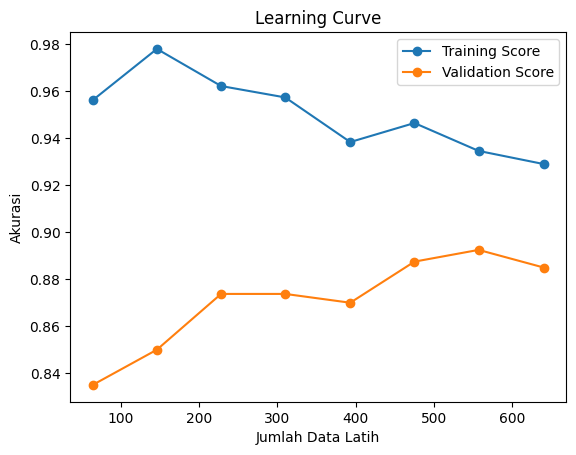

In [17]:
plt.plot(train_sizes,train_mean,'o-',
label='Training Score')
plt.plot(train_sizes,val_mean,'o-',
label='Validation Score')
plt.xlabel('Jumlah Data Latih')
plt.ylabel('Akurasi')
plt.title('Learning Curve')
plt.legend()
plt.show()